In [1]:
import pandas as pd, numpy as np, re
import matplotlib.pyplot as plt
from datasets import load_dataset
from sklearn.linear_model import LogisticRegression

In [2]:
d1 = pd.read_csv("/kaggle/input/datasets/maslenikovapolina/results/results_test100_Qwen2.5-0.5B-Instruct.csv")
d12= pd.read_csv("/kaggle/input/datasets/maslenikovapolina/results/results_test200_Qwen2.5-0.5B-Instruct.csv")
d2 = pd.read_csv("/kaggle/input/datasets/maslenikovapolina/results/results_test100_Qwen2.5-3B-Instruct.csv")
d22= pd.read_csv("/kaggle/input/datasets/maslenikovapolina/results/results_test200_Qwen2.5-3B-Instruct.csv")
d3 = pd.read_csv("/kaggle/input/datasets/maslenikovapolina/results/results_test100_Qwen2.5-7B-Instruct.csv")
d32= pd.read_csv("/kaggle/input/datasets/maslenikovapolina/results/results_test200_Qwen2.5-7B-Instruct.csv")
df = pd.concat([d1,d12, d2,d22, d3,d32], ignore_index=True)

In [3]:
df["model"] = df["model"].str.replace("Qwen/", "").str.replace("-Instruct", "")
print(df.shape, df["model"].unique())

(5400, 15) ['Qwen2.5-0.5B' 'Qwen2.5-3B' 'Qwen2.5-7B']


In [4]:
print(df.groupby(["model", "dataset", "mode"])["question_id"].nunique().unique())

[300]


Таблицы получены отдельным ноутбуком: каждая строка соответствует одному вопросу, одной модели и одному режиму и содержит сгенерированный текст, извлечённый ответ, эталонный ответ, флаг верности (correct), число сгенерированных токенов (n_tokens), флаг обрезки ответа (truncated)(при слишком длинном ответе) и эталонное число шагов для gsm8k(gold_n_steps). Для каждой модели две таблицы: первые 100 вопросов на набор и ещё 200 других вопросов, которые склеиваем в 300.

Датсеты: GSM8K (школьные текстовые задачи по арифметике) и ARC-Challenge (вопросы по естественным наукам с выбором из четырёх вариантов): по 300 случайных вопросов из тестовой части каждого набора. 

Режимы генерации: direct (ответ сразу, без рассуждения), cot (рассуждение по шагам без примеров), fewshot (рассуждение по шагам с тремя примерами из обучающей части)

## Часть 1. Эффект CoT: сравнение режимов

Для каждой модели, набора и режима смотрим три числа: долю верных ответов (accuracy), среднее число сгенерированных токенов и долю обрезанных ответов. 

In [5]:
display(df.pivot_table(index=["dataset", "mode"], columns="model", values="correct"))
display(df.pivot_table(index=["dataset", "mode"], columns="model", values="n_tokens"))
display(df.pivot_table(index=["dataset", "mode"], columns="model", values="truncated"))

model            Qwen2.5-0.5B  Qwen2.5-3B  Qwen2.5-7B
dataset mode                                         
arc     cot          0.360000    0.846667    0.923333
        direct       0.476667    0.820000    0.890000
        fewshot      0.446667    0.840000    0.930000
gsm8k   cot          0.413333    0.866667    0.906667
        direct       0.050000    0.120000    0.183333
        fewshot      0.443333    0.840000    0.920000

model            Qwen2.5-0.5B  Qwen2.5-3B  Qwen2.5-7B
dataset mode                                         
arc     cot        257.190000  263.320000  264.076667
        direct       2.140000    2.000000    2.000000
        fewshot    129.036667   99.513333   88.426667
gsm8k   cot        315.270000  286.716667  274.533333
        direct       3.686667    3.593333    3.476667
        fewshot    253.183333  212.266667  190.646667

model            Qwen2.5-0.5B  Qwen2.5-3B  Qwen2.5-7B
dataset mode                                         
arc     cot          0.000000    0.003333    0.003333
        direct       0.000000    0.000000    0.000000
        fewshot      0.000000    0.000000    0.000000
gsm8k   cot          0.016667    0.006667    0.000000
        direct       0.000000    0.000000    0.003333
        fewshot      0.010000    0.000000    0.000000

Доля обрезанных ответов мала (не больше 2%), так что лимит длины почти не искажает результат. Прямой ответ на GSM8K очень слабый у всех моделей (0.05, 0.12 и 0.18), а с рассуждением 0.41, 0.87 и 0.91. На ARC прямой ответ и CoT близки, кроме 0.5B, у которой CoT хуже (0.36 против 0.48). Токенов CoT тратит на два порядка больше, чем прямой ответ.

Чтобы оценить насколько можно доверять accuracy, используем bootstrap: для каждой группы (модель × набор × режим) 1000 раз пересобираем выборку из тех же 300 ответов (с возвращением) и считаем accuracy. Границы, между которыми лежат средние 95% этих значений, дают 95%-й доверительный интервал.

In [6]:
rng = np.random.default_rng(42)

rows = []
for (model, dataset, mode), g in df.groupby(["model", "dataset", "mode"]):
    x = g["correct"].astype(int).values
    boots = [rng.choice(x, size=len(x), replace=True).mean() for i in range(1000)]
    rows.append(dict(model=model, dataset=dataset, mode=mode, acc=x.mean(),
                     low=np.percentile(boots, 2.5), high=np.percentile(boots, 97.5)))
acc = pd.DataFrame(rows)
acc

,model,dataset,mode,acc,low,high
0,Qwen2.5-0.5B,arc,cot,0.360000,0.303333,0.410000
1,Qwen2.5-0.5B,arc,direct,0.476667,0.420000,0.536667
2,Qwen2.5-0.5B,arc,fewshot,0.446667,0.386667,0.506667
3,Qwen2.5-0.5B,gsm8k,cot,0.413333,0.363250,0.470000
4,Qwen2.5-0.5B,gsm8k,direct,0.050000,0.026667,0.073417
5,Qwen2.5-0.5B,gsm8k,fewshot,0.443333,0.386667,0.496667
6,Qwen2.5-3B,arc,cot,0.846667,0.803333,0.886667
7,Qwen2.5-3B,arc,direct,0.820000,0.773333,0.863333
8,Qwen2.5-3B,arc,fewshot,0.840000,0.800000,0.876667
9,Qwen2.5-3B,gsm8k,cot,0.866667,0.823333,0.906667


Ширина интервалов около +-3-6 процентных пунктов. На GSM8K режимы с рассуждением значительно лучше прямого ответа у всех моделей (интервалы не пересекаются). На ARC у 3B и 7B интервалы всех режимов перекрываются, у 0.5B CoT заметно хуже прямого ответа.

Для каждого вопроса берём разницу «верно в режиме CoT минус верно в режиме direct» (принимает значения −1, 0 или +1) и усредняем. Так лёгкие и трудные вопросы не мешают сравнению, потому что в обоих режимах это одни и те же вопросы. Интервал снова считаем bootstrap.

In [7]:
wide = df.pivot_table(index=["model", "dataset", "question_id"], columns="mode", values="correct").reset_index()

rows = []
for (model, dataset), g in wide.groupby(["model", "dataset"]):
    for mode in ["cot", "fewshot"]:
        d = (g[mode] - g["direct"]).values
        boots = [rng.choice(d, size=len(d), replace=True).mean() for i in range(1000)]
        rows.append(dict(model=model, dataset=dataset, comparison=mode + " - direct",
                         diff=d.mean(), low=np.percentile(boots, 2.5), high=np.percentile(boots, 97.5)))
effect = pd.DataFrame(rows)
effect

,model,dataset,comparison,diff,low,high
0,Qwen2.5-0.5B,arc,cot - direct,-0.116667,-0.193333,-0.040000
1,Qwen2.5-0.5B,arc,fewshot - direct,-0.030000,-0.093333,0.033333
2,Qwen2.5-0.5B,gsm8k,cot - direct,0.363333,0.300000,0.423333
3,Qwen2.5-0.5B,gsm8k,fewshot - direct,0.393333,0.326667,0.453333
4,Qwen2.5-3B,arc,cot - direct,0.026667,-0.013333,0.066667
5,Qwen2.5-3B,arc,fewshot - direct,0.020000,-0.016667,0.063333
6,Qwen2.5-3B,gsm8k,cot - direct,0.746667,0.696667,0.793333
7,Qwen2.5-3B,gsm8k,fewshot - direct,0.720000,0.670000,0.773333
8,Qwen2.5-7B,arc,cot - direct,0.033333,-0.006667,0.070000
9,Qwen2.5-7B,arc,fewshot - direct,0.040000,0.006667,0.073333


На GSM8K CoT даёт +0.36 (0.5B), +0.75 (3B), +0.72 (7B), а на ARC от −0.12 до +0.03. 
Для few-shot картина похожая: на GSM8K +0.39, +0.72 и +0.74, на ARC −0.03, +0.02 и +0.04 (для 7B интервал [0.01; 0.07] едва выше нуля)

**Гипотеза 1: у малых моделей CoT помогает слабее или вредит. Подтверждена частично.**

На GSM8K выигрыш у 0.5B (+0.36) примерно вдвое меньше, чем у 3B и 7B, интервалы не пересекаются. Между 3B и 7B различия минимальны. На ARC у 0.5B CoT ухудшает ответ (−0.12), у 3B и 7B эффекта не видно: интервалы включают ноль.

**Гипотеза 2: на GSM8K выигрыш от CoT больше, чем на ARC. Подтверждена.**

Разность CoT минус прямой ответ на GSM8K: 0.5B +0.36 [0.30; 0.42], 3B +0.75 [0.70; 0.79], 7B +0.72 [0.67; 0.78]. На ARC: 0.5B −0.12 [−0.19; −0.04], 3B +0.03 [−0.01; 0.07], 7B +0.03 [-0.01;0.07] Для каждой модели интервалы двух наборов не пересекаются.

Для каждого набора строим график точности: по оси X модели от меньшей к большей, по оси Y accuracy. 

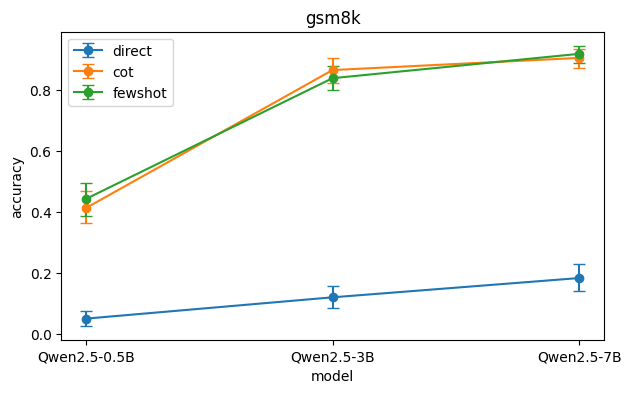

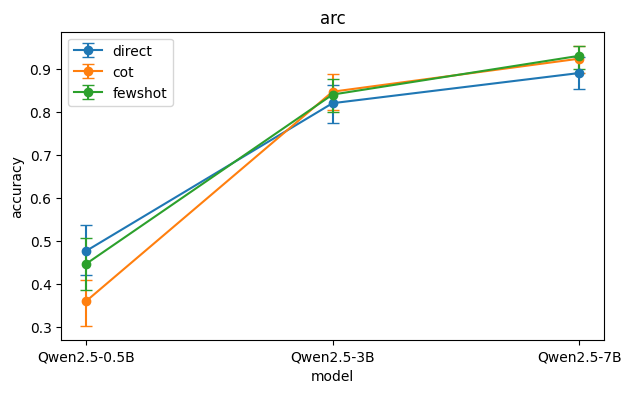

In [8]:
for dataset in ["gsm8k", "arc"]:
    a = acc[acc["dataset"] == dataset]
    plt.figure(figsize=(7, 4))
    for mode in ["direct", "cot", "fewshot"]:
        b = a[a["mode"] == mode]
        plt.errorbar(b["model"], b["acc"], yerr=[b["acc"] - b["low"], b["high"] - b["acc"]],
                     marker="o", capsize=4, label=mode)
    plt.title(dataset)
    plt.xlabel("model")
    plt.ylabel("accuracy")
    plt.legend()
    plt.show()

На GSM8K линия direct лежит у самого низа для всех моделей, а cot и fewshot почти совпадают и растут от 0.5B к 3B, дальше рост замедляется. На ARC три линии идут близко, кроме точки 0.5B, где cot ниже остальных.

Рассуждение стоит токенов: чем длиннее ответ, тем дороже и медленнее генерация. Смотрим среднее число сгенерированных токенов по режимам. Учитываются только токены ответа, без учёта примеров в few-shot режиме.

In [9]:
tokens = df.groupby(["model", "dataset", "mode"])["n_tokens"].mean().reset_index()
tokens

,model,dataset,mode,n_tokens
0,Qwen2.5-0.5B,arc,cot,257.190000
1,Qwen2.5-0.5B,arc,direct,2.140000
2,Qwen2.5-0.5B,arc,fewshot,129.036667
3,Qwen2.5-0.5B,gsm8k,cot,315.270000
4,Qwen2.5-0.5B,gsm8k,direct,3.686667
5,Qwen2.5-0.5B,gsm8k,fewshot,253.183333
6,Qwen2.5-3B,arc,cot,263.320000
7,Qwen2.5-3B,arc,direct,2.000000
8,Qwen2.5-3B,arc,fewshot,99.513333
9,Qwen2.5-3B,gsm8k,cot,286.716667


CoT генерирует 257-315 токенов против 2-4 у прямого ответа, то есть в 80-130 раз больше. Few-shot даёт более короткие ответы, чем zero-shot CoT (7B на GSM8K: 191 против 275), при близкой точности.

Сравниваем режимы fewshot и cot по одним и тем же вопросам: берём разность «верно в fewshot минус верно в cot» с bootstrap-интервалом, а для токенов считаем долю экономии: 1 − (токены fewshot / токены cot).

In [10]:
rows = []
for (model, dataset), g in wide.groupby(["model", "dataset"]):
    d = (g["fewshot"] - g["cot"]).values
    boots = [rng.choice(d, size=len(d), replace=True).mean() for i in range(1000)]
    rows.append(dict(model=model, dataset=dataset, comparison="fewshot - cot",
                     diff=d.mean(), low=np.percentile(boots, 2.5), high=np.percentile(boots, 97.5)))
fs_vs_cot = pd.DataFrame(rows)
fs_vs_cot

,model,dataset,comparison,diff,low,high
0,Qwen2.5-0.5B,arc,fewshot - cot,0.086667,0.019917,0.156667
1,Qwen2.5-0.5B,gsm8k,fewshot - cot,0.030000,-0.030000,0.083333
2,Qwen2.5-3B,arc,fewshot - cot,-0.006667,-0.053333,0.036667
3,Qwen2.5-3B,gsm8k,fewshot - cot,-0.026667,-0.063333,0.006667
4,Qwen2.5-7B,arc,fewshot - cot,0.006667,-0.026667,0.040000
5,Qwen2.5-7B,gsm8k,fewshot - cot,0.013333,-0.010000,0.036667


Few-shot против рассуждения без примеров

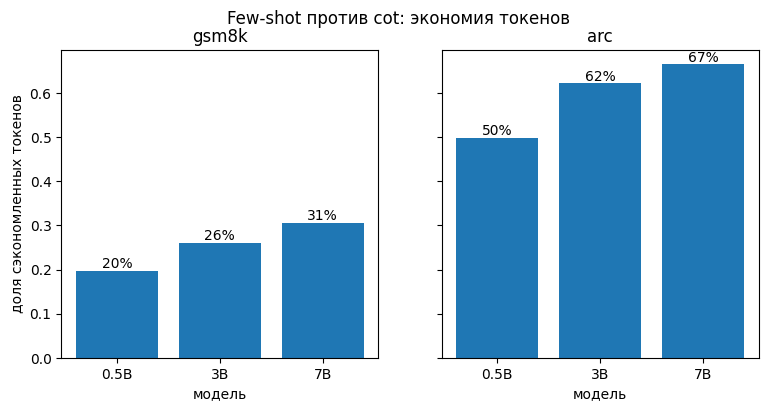

In [11]:
models = ["Qwen2.5-0.5B", "Qwen2.5-3B", "Qwen2.5-7B"]

t = df.pivot_table(index=["dataset", "model"], columns="mode", values="n_tokens")
saving = 1 - t["fewshot"] / t["cot"]

fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharey=True)
for ax, dataset in zip(axes, ["gsm8k", "arc"]):
    s = saving[dataset].loc[models]
    bars = ax.bar([m.replace("Qwen2.5-", "") for m in models], s.values)
    ax.bar_label(bars, labels=[f"{v:.0%}" for v in s.values])
    ax.set_title(dataset)
    ax.set_xlabel("модель")
axes[0].set_ylabel("доля сэкономленных токенов")
fig.suptitle("Few-shot против cot: экономия токенов")
plt.show()

**Гипотеза 3: Few-shot с тремя примерами (GSM8K: решения из обучающей части набора; ARC: самостоятельно написанные короткие рассуждения) даёт такую же точность, как cot без примеров, но с меньшим числом сгенерированных токенов. Подтверждена.**

В пяти из шести случаев интервал включает ноль, то есть различий в точности не видно. У 0.5B на ARC few-shot даже лучше (+0.09). Ни в одном случае few-shot не оказался заметно хуже. Few-shot пишет короче во всех случаях, экономия растёт с размером модели и больше на ARC.

*Считаются только сгенерированные токены, подсказка с примерами у few-shot длиннее, поэтому общая стоимость запроса может отличаться. 

## Часть 2. От чего зависит выигрыш от CoT на GSM8K

Смотрим только вопросы GSM8K (у ARC нет эталонных решений, поэтому число шагов посчитать нельзя). Сложность вопроса измеряем двумя способами: числом шагов в эталонном решении и длиной текста вопроса в словах. 

In [13]:
gsm_test = load_dataset("openai/gsm8k", "main", split="test")

gs = df[df["dataset"] == "gsm8k"].copy()
gs["question"] = gs["question_id"].str.split("_").str[1].astype(int).apply(lambda i: gsm_test[int(i)]["question"])
gs["q_len"] = gs["question"].str.split().str.len()
gs[["gold_n_steps", "q_len"]].describe()

README.md:   0%|          | 0.00/7.93k [00:00<?, ?B/s]

main/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.31MB            

main/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

main/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  419kB            

main/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/7473 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1319 [00:00<?, ? examples/s]

,gold_n_steps,q_len
count,2700.000000,2700.000000
mean,3.680000,46.153333
std,1.507241,18.809595
min,2.000000,19.000000
25%,3.000000,32.000000
50%,3.000000,43.000000
75%,4.000000,55.250000
max,9.000000,129.000000


Cмотрим распределение эталонного решения: от 2 до 9 шагов, чаще всего 3.

In [14]:
print(gs.drop_duplicates('question_id')["gold_n_steps"].value_counts())

gold_n_steps
3.0    83
4.0    74
2.0    74
5.0    28
6.0    23
7.0    12
8.0     5
9.0     1
Name: count, dtype: int64


Вопросов с 6 и более шагами мало по сравнению с количеством шагов от 2 до 4, поэтому объединяем всё от 5 шагов в одну группу.

In [15]:
gs["steps_group"] = gs["gold_n_steps"].clip(upper=5)

print(gs.drop_duplicates('question_id')["steps_group"].value_counts())

tab = gs.pivot_table(index=["model", "steps_group"], columns="mode", values="correct")
tab["cot - direct"] = tab["cot"] - tab["direct"]
tab

steps_group
3.0    83
4.0    74
2.0    74
5.0    69
Name: count, dtype: int64


mode                           cot    direct   fewshot  cot - direct
model        steps_group                                            
Qwen2.5-0.5B 2.0          0.608108  0.067568  0.567568      0.540541
             3.0          0.433735  0.060241  0.506024      0.373494
             4.0          0.351351  0.040541  0.432432      0.310811
             5.0          0.246377  0.028986  0.246377      0.217391
Qwen2.5-3B   2.0          0.945946  0.283784  0.945946      0.662162
             3.0          0.915663  0.084337  0.879518      0.831325
             4.0          0.797297  0.067568  0.770270      0.729730
             5.0          0.797101  0.043478  0.753623      0.753623
Qwen2.5-7B   2.0          0.972973  0.391892  0.986486      0.581081
             3.0          0.939759  0.180723  0.951807      0.759036
             4.0          0.837838  0.108108  0.878378      0.729730
             5.0          0.869565  0.043478  0.855072      0.826087

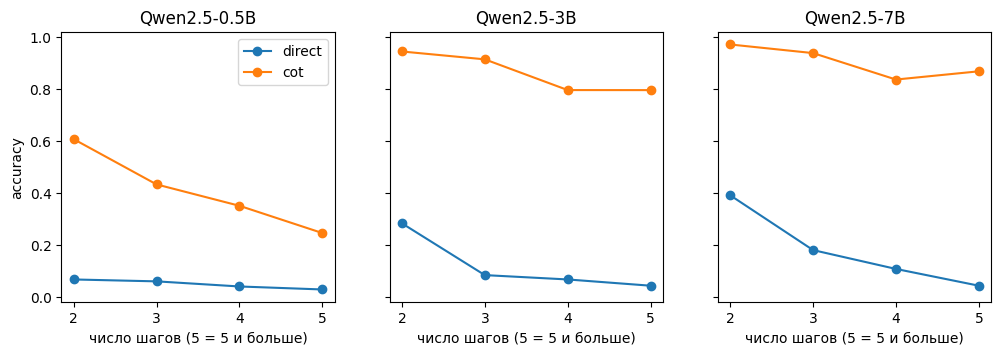

In [16]:
models = ["Qwen2.5-0.5B", "Qwen2.5-3B", "Qwen2.5-7B"]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
for ax, model in zip(axes, models):
    ax.plot(tab.loc[model].index, tab.loc[model]["direct"], marker="o", label="direct")
    ax.plot(tab.loc[model].index, tab.loc[model]["cot"], marker="o", label="cot")
    ax.set_title(model)
    ax.set_xlabel("число шагов (5 = 5 и больше)")
axes[0].set_ylabel("accuracy")
axes[0].legend()
plt.show()

Accuracy падает с ростом числа шагов в эталонном решении у всех моделей: у 0.5B с рассуждением с 0.61 (2 шага) до 0.25 (5 и больше), у 7B с рассуждением с 0.97 до 0.87, а прямой ответ у 7B с 0.39 до 0.04. Выигрыш от рассуждения (разность cot − direct) не растёт монотонно: у 0.5B он падает (0.54 -> 0.22), у 3B держится около 0.7-0.8, у 7B растёт (0.58 -> 0.83), в основном за счёт того, что прямой ответ упирается в ноль.

Корреляция числа шагов и длины вопроса 0.41: умеренная, признаки связаны, но разделить их влияние можно.

In [17]:
gs.drop_duplicates("question_id")[["gold_n_steps", "q_len"]].corr()

,gold_n_steps,q_len
gold_n_steps,1.000000,0.405165
q_len,0.405165,1.000000


Модель пишет примерно вдвое больше блоков текста, чем строк в эталонном решении (6-8 против 3.7): вступление, заключение и формулы идут отдельными блоками. У неверных ответов блоков больше, чем у верных (0.5B 8.2 и 7.3; 3B 8.5 и 6.8; 7B 7.5 и 5.9). Это описательное наблюдение: трудные вопросы требуют длинных рассуждений и чаще дают ошибки

In [18]:
c = gs[gs["mode"] == "cot"].copy()
c["correct"] = c["correct"].astype(int)
print(c.groupby("model")[["n_steps", "gold_n_steps"]].mean())
print(c.groupby(["model", "correct"])["n_steps"].mean())

               n_steps  gold_n_steps
model                               
Qwen2.5-0.5B  7.846667          3.68
Qwen2.5-3B    7.060000          3.68
Qwen2.5-7B    6.053333          3.68
model         correct
Qwen2.5-0.5B  0          8.244318
              1          7.282258
Qwen2.5-3B    0          8.475000
              1          6.842308
Qwen2.5-7B    0          7.464286
              1          5.908088
Name: n_steps, dtype: float64


Для каждой модели строим регрессию на строках direct и cot. Интервалы коэффициентов получены пересборкой вопросов (200 повторов), потому что один вопрос встречается в двух режимах. Коэффициенты в логарифмах шансов: смотрим на знак и на то, содержит ли интервал ноль.

С помощью логистической регресии посмотрим от чего зависит эффект CoT:

is_cot: общий уровень различия режимов

steps_x_cot: зависит ли эффект CoT от количества шагов решения?

qlen_x_cot: зависит ли от длины вопроса?

gold_n_steps: зависит ли от количества шагов в эталонном решении?

q_len10: Связана ли длина вопроса с вероятностью правильного ответа?

In [21]:
sub = gs[gs["mode"].isin(["direct", "cot"])].copy()
sub["correct"] = sub["correct"].astype(int)
sub["is_cot"] = (sub["mode"] == "cot").astype(int)
sub["q_len10"] = sub["q_len"] / 10
sub["steps_x_cot"] = sub["is_cot"] * sub["gold_n_steps"]
sub["qlen_x_cot"] = sub["is_cot"] * sub["q_len10"]
cols = ["is_cot","gold_n_steps", "q_len10", "steps_x_cot", "qlen_x_cot"]

rng = np.random.default_rng(42)
rows = []
for model_name, d in sub.groupby("model"):
    by_q = {q: d[d["question_id"] == q] for q in d["question_id"].unique()}
    full = LogisticRegression(max_iter=1000).fit(d[cols], d["correct"]).coef_[0]
    coefs = []
    for b in range(200):
        pick = rng.choice( d["question_id"].unique(), size=len( d["question_id"].unique()), replace=True)
        boot = pd.concat([by_q[q] for q in pick])
        coefs.append(LogisticRegression(max_iter=1000).fit(boot[cols], boot["correct"]).coef_[0])
    coefs = np.array(coefs)
    for j, name in enumerate(cols):
        rows.append(dict(model=model_name, term=name, coef=full[j],low=np.percentile(coefs[:, j], 2.5), high=np.percentile(coefs[:, j], 97.5)))
pd.DataFrame(rows).round(3)

,model,term,coef,low,high
0,Qwen2.5-0.5B,is_cot,2.094,1.250,2.928
1,Qwen2.5-0.5B,gold_n_steps,-0.546,-1.063,-0.188
2,Qwen2.5-0.5B,q_len10,-0.135,-0.410,0.114
3,Qwen2.5-0.5B,steps_x_cot,0.363,-0.037,0.872
4,Qwen2.5-0.5B,qlen_x_cot,-0.162,-0.469,0.165
5,Qwen2.5-3B,is_cot,2.289,1.048,3.276
6,Qwen2.5-3B,gold_n_steps,-0.873,-1.386,-0.477
7,Qwen2.5-3B,q_len10,-0.173,-0.529,0.067
8,Qwen2.5-3B,steps_x_cot,0.794,0.446,1.293
9,Qwen2.5-3B,qlen_x_cot,-0.158,-0.427,0.162


**Гипотеза 4: Выигрыш от CoT растёт с числом шагов в эталонном решении. Подтверждена только для более крупных моделей.** 
У 3B (+0.79 [0.45; 1.29]) и 7B (+0.63 [0.29; 1.06]) интервалы взаимодействия «число шагов × рассуждение» не включают ноль: с ростом числа шагов точность прямого ответа падает быстрее, чем с рассуждением, то есть преимущество рассуждения растёт. У 0.5B оценка тоже положительна (+0.36), но интервал [−0.04; 0.87] включает ноль. 

**Гипотеза 5: Длина текста вопроса не влияет на выигрыш от CoT. Подтверждена.** 

Взаимодействие «длина вопроса × рассуждение» включает ноль у всех моделей (0.5B −0.16 [−0.47; 0.17], 3B −0.16 [−0.43; 0.16], 7B +0.13 [−0.15; 0.41]): длина вопроса не меняет выигрыш от рассуждения.